In [ ]:
!pip install pydot
!apt-get install -y graphviz

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 52 not upgraded.


In [ ]:
import os, cv2, random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from tqdm import tqdm
from random import shuffle
from IPython.display import SVG
from tensorflow.keras.utils import model_to_dot, plot_model
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D
# model_to_dot cần cài thêm pydot + graphviz, nếu chỉ cần visualize thì dùng plot_model là đủ
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/dogs-cats-database/processed/'
os.makedirs(SAVE_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
model = load_model(SAVE_DIR + 'model_final.keras')
model.summary()  # kiểm tra load đúng model

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,600,008 (90.03 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 8,198 (32.03 KB)

In [ ]:
TEST_SIZE = 0.5
RANDOM_STATE = 2018
BATCH_SIZE = 32
NO_EPOCHS = 20
NUM_CLASSES = 2
SAMPLE_SIZE = 7000
IMG_SIZE = 224 # Changed to 224 to align with ResNet50 input requirements

# Đường dẫn dữ liệu - trỏ vào thư mục trên Colab (sau khi tải/giải nén)
PATH = '/content/drive/MyDrive/dogs-cats-database/'
TRAIN_FOLDER = PATH + 'training_set/'
TEST_FOLDER = PATH + 'test_set/'

# Không cần file trọng số .h5 tải sẵn nữa - để Keras tự tải weights ImageNet
# (xem giải thích bên dưới)

In [ ]:
# import os, cv2, random
# import numpy as np
# from tqdm import tqdm
# from random import shuffle

# def get_image_list(folder):
#     image_list = []
#     for label_folder in os.listdir(folder):
#         sub_path = os.path.join(folder, label_folder)
#         if os.path.isdir(sub_path):
#             for fname in os.listdir(sub_path):
#                 image_list.append(os.path.join(label_folder, fname))
#     return image_list

# train_image_list = get_image_list(TRAIN_FOLDER)
# # For test images, assume they are directly in TEST_FOLDER, not in subfolders.
# test_image_list  = os.listdir(TEST_FOLDER)

# print(len(train_image_list), len(test_image_list))

# # ----- Gán nhãn theo tên thư mục -----
# def label_pet_image_one_hot_encoder(img):
#     # Extract the label from the folder name, e.g., 'cats/cat.123.jpg' -> 'cats'
#     label_folder = img.split('/')[0]
#     if label_folder == 'cats':
#         return [1, 0]
#     elif label_folder == 'dogs':
#         return [0, 1]
#     return None # Return None if label is not 'cats' or 'dogs'

# ----- Đọc + resize ảnh -----
# def process_data(data_image_list, DATA_FOLDER, isTrain=True):
#     data_df = []
#     for img in tqdm(data_image_list):
#         path = os.path.join(DATA_FOLDER, img)
#         label = None
#         if(isTrain):
#             label = label_pet_image_one_hot_encoder(img)
#             # Add this check to skip images with unidentifiable labels during training
#             if label is None:
#                 continue
#         else:
#             # For test images, if no label is directly available, we can use the filename as an identifier.
#             # Assuming test image names are like 'id.jpg'
#             label = img.split('.')[0] # e.g., '123.jpg' -> '123'

#         img_data = cv2.imread(path, cv2.IMREAD_COLOR)

#         # Thêm kiểm tra: nếu ảnh lỗi/hỏng, cv2.imread trả về None -> bỏ qua thay vì crash
#         if img_data is None:
#             print(f"Bỏ qua ảnh lỗi: {path}")
#             continue

#         img_data = cv2.resize(img_data, (IMG_SIZE, IMG_SIZE))
#         data_df.append([np.array(img_data), np.array(label)])
#     shuffle(data_df)
#     return data_df

X = np.load(SAVE_DIR + 'X.npy')
y = np.load(SAVE_DIR + 'y.npy')
X_test = np.load(SAVE_DIR + 'X_test.npy')
ids_test = np.load(SAVE_DIR + 'ids_test.npy')

print(X.shape, y.shape, X_test.shape)

(6469, 224, 224, 3) (6469, 2) (200, 224, 224, 3)


In [ ]:
with open(SAVE_DIR + 'training_history.pkl', 'rb') as f:
    history = pickle.load(f)

print(history.keys())  # dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [ ]:
# This cell was previously used for function definitions but is now cleared to avoid conflicts.
# The updated definitions for label_pet_image_one_hot_encoder and process_data are now in cell 2-59irwZZeLU.

In [ ]:
# def plot_image_list_count(data_image_list):
#     labels = []
#     for img in data_image_list:
#         # Correctly extract label from image path (e.g., 'cats/cat.123.jpg' -> 'cats')
#         label_folder = img.split('/')[0]
#         labels.append(label_folder)

#     sns.countplot(x=labels)
#     plt.title('Cats and Dogs')
#     plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.5       # nhớ dùng đúng giá trị như lần train trước, để tránh lệch kết quả so sánh
RANDOM_STATE = 2018

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [ ]:
# #def show_images(data, isTest=False):
#     f, ax = plt.subplots(5, 5, figsize=(15, 15))
#     for i, img_item in enumerate(data[:25]):
#         img_num = img_item[1]
#         img_data = img_item[0]

#         img_data_rgb = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)  # sửa màu để hiển thị đúng

#         label = np.argmax(img_num) if not isTest else None
#         if isTest:
#             str_label = "None"
#         elif label == 1:
#             str_label = 'Dog'
#         elif label == 0:
#             str_label = 'Cat'

#         ax[i//5, i%5].imshow(img_data_rgb)
#         ax[i//5, i%5].axis('off')
#         ax[i//5, i%5].set_title("Label: {}".format(str_label))
#     plt.show()

# show_images(train)
# show_images(test, True)

In [ ]:
# # Phần train: dùng code của bạn
# X = np.array([i[0] for i in train]).reshape(-1, IMG_SIZE, IMG_SIZE, 3)
# y = np.array([i[1] for i in train])

# # Phần test: vẫn cần thêm (code của bạn chưa có)
# X_test   = np.array([i[0] for i in test]).reshape(-1, IMG_SIZE, IMG_SIZE, 3)
# ids_test = np.array([i[1] for i in test])

# # Lưu lại
# np.save(SAVE_DIR + 'X.npy', X)
# np.save(SAVE_DIR + 'y.npy', y)
# np.save(SAVE_DIR + 'X_test.npy', X_test)
# np.save(SAVE_DIR + 'ids_test.npy', ids_test)

In [ ]:
# model = Sequential()
# model.add(ResNet50(
#     include_top=False,
#     pooling='max',
#     weights='imagenet',              # sửa: dùng weights='imagenet' thay vì file path Kaggle
#     input_shape=(IMG_SIZE, IMG_SIZE, 3)   # thêm: bắt buộc phải khai báo khi include_top=False
# ))
# model.add(Dense(NUM_CLASSES, activation='softmax'))

# # Sửa: đặt False để giữ đúng tinh thần Transfer Learning (đóng băng ResNet50, chỉ train lớp Dense mới thêm)
# model.layers[0].trainable = False

# model.compile(
#     optimizer='adam',
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )


In [ ]:
# model.compile(
#     optimizer='adam',
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )

In [ ]:
# model.summary()
# plot_model(model, to_file='model.png', show_shapes=True)  # thêm show_shapes=True cho dễ nhìn
# SVG(model_to_dot(model).create(prog='dot', format='svg'))

In [ ]:
# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [ ]:
# train_model = model.fit(X_train, y_train,
#                   batch_size=BATCH_SIZE,
#                   epochs=NO_EPOCHS,
#                   verbose=1,
#                   validation_data=(X_val, y_val))

# Train tiếp
train_model_2 = model.fit(X_train, y_train,
                  batch_size=32,
                  epochs=30,
                  initial_epoch=20,     # tiếp tục đúng từ epoch đã train trước
                  verbose=1,
                  validation_data=(X_val, y_val))

# Hoặc chỉ để dự đoán/đánh giá, không train nữa
# predictions = model.predict(X_test)

Epoch 21/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 36s 293ms/step - accuracy: 1.0000 - loss: 8.5387e-05 - val_accuracy: 0.9793 - val_loss: 0.1376
Epoch 22/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 270ms/step - accuracy: 1.0000 - loss: 8.2287e-05 - val_accuracy: 0.9793 - val_loss: 0.1380
Epoch 23/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 40s 263ms/step - accuracy: 1.0000 - loss: 7.7852e-05 - val_accuracy: 0.9790 - val_loss: 0.1376
Epoch 24/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 270ms/step - accuracy: 1.0000 - loss: 7.3951e-05 - val_accuracy: 0.9793 - val_loss: 0.1380
Epoch 25/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 263ms/step - accuracy: 1.0000 - loss: 6.9445e-05 - val_accuracy: 0.9790 - val_loss: 0.1376
Epoch 26/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 263ms/step - accuracy: 1.0000 - loss: 6.8002e-05 - val_accuracy: 0.9793 - val_loss: 0.1377
Epoch 27/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 264ms/step - accuracy: 1.0000 - loss: 6.3814e-05 - val_accuracy: 0.9793 - val_loss: 0.1381
Epoch 28/30
102/102 ━━━━━━━━━━━━━━━━━━━━ 27s 264

In [ ]:
model.save(SAVE_DIR + 'model.keras')

In [ ]:
import os, cv2
import numpy as np

IMG_SIZE = 224  # phải khớp với lúc train

def load_new_images(folder):
    """Đọc toàn bộ ảnh trong 1 thư mục, không cần nhãn"""
    image_list = []
    filenames = []
    for fname in os.listdir(folder):
        path = os.path.join(folder, fname)
        img_data = cv2.imread(path, cv2.IMREAD_COLOR)
        if img_data is None:
            print(f"Bỏ qua ảnh lỗi: {path}")
            continue
        img_data = cv2.resize(img_data, (IMG_SIZE, IMG_SIZE))
        image_list.append(img_data)
        filenames.append(fname)
    return np.array(image_list), filenames

NEW_TEST_FOLDER = '/content/drive/MyDrive/dogs-cats-database/test_2/'
X_new, filenames_new = load_new_images(NEW_TEST_FOLDER)

print(X_new.shape)

(40, 224, 224, 3)


In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
import cv2

def show_predictions_random(X_new, filenames_new, predictions, num_images=25, cols=5, seed=None):
    if seed is not None:
        random.seed(seed)

    predicted_classes = np.argmax(predictions, axis=1)
    confidences = np.max(predictions, axis=1)

    n = min(num_images, len(X_new))
    random_indices = random.sample(range(len(X_new)), n)  # chọn ngẫu nhiên không trùng

    rows = (n + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
    ax = ax.flatten() if n > 1 else [ax]

    for i, idx in enumerate(random_indices):
        img_rgb = cv2.cvtColor(X_new[idx].astype('uint8'), cv2.COLOR_BGR2RGB)
        label = 'Dog' if predicted_classes[idx] == 1 else 'Cat'
        conf = confidences[idx] * 100

        ax[i].imshow(img_rgb)
        ax[i].axis('off')
        ax[i].set_title(f"{label} ({conf:.1f}%)\n{filenames_new[idx]}", fontsize=9)

    for j in range(n, len(ax)):
        ax[j].axis('off')

    plt.tight_layout()
    plt.show()

show_predictions_random(X_new, filenames_new, predictions, num_images=10)

In [ ]:
#Vẽ biểu đồ accuracy/loss
def plot_accuracy_and_loss(train_model):
    hist = train_model.history
    acc = hist['accuracy']            # sửa: 'acc' -> 'accuracy'
    val_acc = hist['val_accuracy']    # sửa: 'val_acc' -> 'val_accuracy'
    loss = hist['loss']
    val_loss = hist['val_loss']
    epochs = range(len(acc))
    f, ax = plt.subplots(1, 2, figsize=(14, 6))
    ax[0].plot(epochs, acc, 'g', label='Training accuracy')
    ax[0].plot(epochs, val_acc, 'r', label='Validation accuracy')
    ax[0].set_title('Training and validation accuracy')
    ax[0].legend()
    ax[1].plot(epochs, loss, 'g', label='Training loss')
    ax[1].plot(epochs, val_loss, 'r', label='Validation loss')
    ax[1].set_title('Training and validation loss')
    ax[1].legend()
    plt.show()

# plot_accuracy_and_loss(train_model)

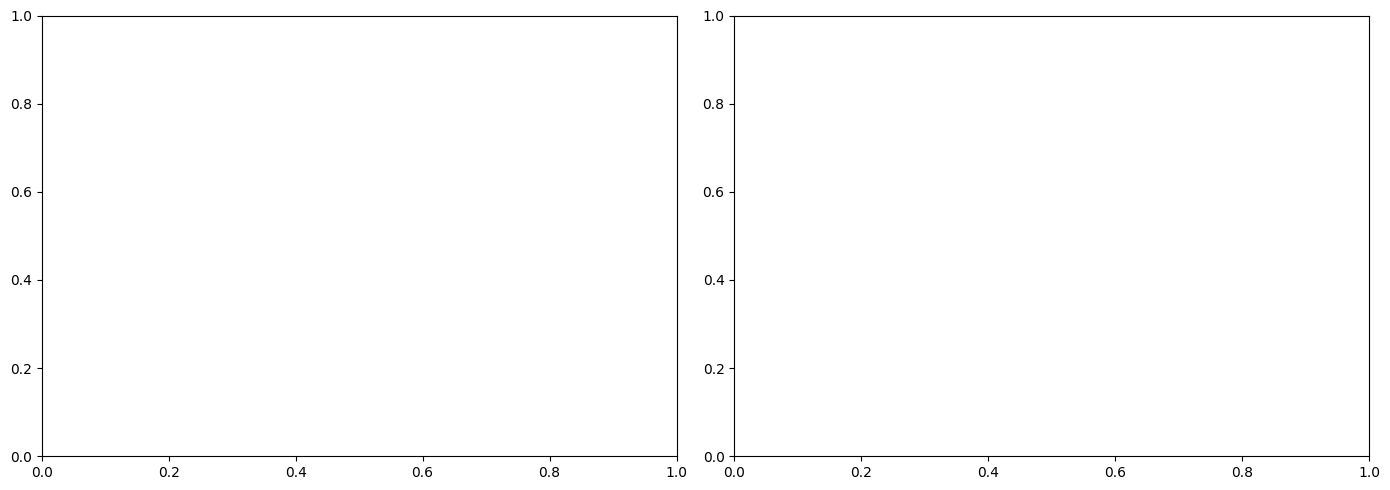

Đã lưu biểu đồ tại: /content/drive/MyDrive/dogs-cats-database/processed/training_curves.png


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# ax[0].plot(train_model.history['loss'], label='train_loss')
# ax[0].plot(train_model.history['val_loss'], label='val_loss')
# ax[0].set_title('Loss qua từng epoch')
# ax[0].set_xlabel('Epoch')
# ax[0].legend()

# ax[1].plot(train_model.history['accuracy'], label='train_accuracy')
# ax[1].plot(train_model.history['val_accuracy'], label='val_accuracy')
# ax[1].set_title('Accuracy qua từng epoch')
# ax[1].set_xlabel('Epoch')
# ax[1].legend()

plt.tight_layout()
plt.savefig(SAVE_DIR + 'training_curves.png', dpi=150)
plt.show()

print("Đã lưu biểu đồ tại:", SAVE_DIR + 'training_curves.png')

In [ ]:
# #Đánh giá số liệu tổng quát
# score = model.evaluate(X_val, y_val, verbose=0)
# print('Validation loss:', score[0])
# print('Validation accuracy:', score[1])

In [ ]:
# # Sửa: model.predict_classes() đã bị xóa - thay bằng predict() + argmax thủ công
# predictions = model.predict(X_val)
# predicted_classes = np.argmax(predictions, axis=1)

# y_true = np.argmax(y_val, axis=1)

In [ ]:
# correct = np.nonzero(predicted_classes == y_true)[0]
# incorrect = np.nonzero(predicted_classes != y_true)[0]

In [ ]:
# target_names = ["Class {}:".format(i) for i in range(NUM_CLASSES)]
# actual_classes = np.unique(np.concatenate((y_true, predicted_classes)))
# filtered_target_names = [target_names[i] for i in actual_classes]
# print(classification_report(y_true, predicted_classes, labels=actual_classes, target_names=filtered_target_names))

In [ ]:
# f, ax = plt.subplots(5, 5, figsize=(15, 15))
# for i, data in enumerate(test[:25]):
#     img_num = data[1]
#     img_data = data[0]
#     orig = cv2.cvtColor(img_data, cv2.COLOR_BGR2RGB)   # sửa: chuyển màu để hiển thị đúng

#     input_data = img_data.reshape(-1, IMG_SIZE, IMG_SIZE, 3)
#     model_out = model.predict(input_data, verbose=0)[0]  # sửa: bỏ dấu ngoặc vuông thừa quanh input_data

#     if np.argmax(model_out) == 1:
#         str_predicted = 'Dog'
#     else:
#         str_predicted = 'Cat'
#     ax[i//5, i%5].imshow(orig)
#     ax[i//5, i%5].axis('off')
#     ax[i//5, i%5].set_title("Predicted:{}".format(str_predicted))
# plt.show()

In [ ]:
pred_list = []
img_list = []
for img in tqdm(test):
    img_data = img[0]
    img_idx = img[1]
    input_data = img_data.reshape(-1, IMG_SIZE, IMG_SIZE, 3)
    predicted = model.predict(input_data, verbose=0)[0]   # sửa: bỏ [ ] thừa, thêm verbose=0
    img_list.append(img_idx)
    pred_list.append(predicted[1])   # predicted[1] = xác suất là "Dog" (theo one-hot [cat, dog])

NameError: name 'test' is not defined

In [ ]:
test  = process_data(test_image_list, TEST_FOLDER, isTrain=False)